# CropGuard AI — Module 08: U-Net Foliar Lesion Segmentation
## Pixel-Level Pathology Localization & Severity Quantification on PlantSeg

Welcome to **Module 08** of the CropGuard AI Deep Learning Series!

Having established high-accuracy disease classification with ResNet50 (98.42% accuracy on 10,999 held-out PlantVillage test images), we now advance to the second core pillar of CropGuard AI: **Foliar Pathology Segmentation**.

While classification answers **"What pathogen is afflicting this plant?"**, it cannot identify **where** the necrotic or chlorotic lesions are situated, nor can it estimate **how severely** the photosynthetic tissue has been compromised. In this module, we introduce the **U-Net architecture** (Ronneberger et al., 2015), an elegant convolutional encoder-decoder network engineered for dense pixel-level prediction.

Using the **PlantSeg benchmark** (11,458 paired leaf images and expert annotations across 115 crop diseases), we will explore the theory, mathematical foundations, data pipelines, loss formulations, and diagnostic evaluations needed to delineate foliar lesions.

---

### Core Learning Objectives
1. **Classification vs. Semantic Segmentation:** Distinguish whole-image label prediction from dense pixel classification and understand why segmentation is essential for severity estimation.
2. **The U-Net Topology:** Master the symmetric contracting encoder and expanding decoder pathways.
3. **Skip Connections:** Understand how concatenating high-resolution shallow features with deep semantic representations preserves fine lesion boundaries.
4. **PlantSeg Data Architecture:** Inspect image-mask pairing, 8-bit grayscale disease index annotations, binarization, and camera EXIF orientation handling.
5. **Combined BCE + Dice Loss:** Overcome severe foliar class imbalance (lesions covering 1–8% of leaf area) using a mathematically grounded compound objective.
6. **Empirical Evaluation:** Track Sørensen-Dice coefficient and Jaccard Index (IoU) across training epochs.
7. **Severity Quantification:** Extract actionable foliar lesion area percentages from predicted masks.
8. **Academic Defense Preparation:** Master 10 comprehensive viva questions covering segmentation theory and practice.


---
## Topic 1: Classification vs Semantic Segmentation

### A. Conceptual Explanation
In computer vision, agricultural diagnostic tasks are categorized by their spatial granularity:
1. **Image Classification:** Predicts a single categorical label $\hat{y} \in \{1, \dots, K\}$ for an entire image $\mathbf{X}$. The network aggregates all spatial features into a one-dimensional vector, discarding coordinate information.
2. **Object Detection:** Localizes pathogens or pests with rectangular bounding boxes $[x_{\min}, y_{\min}, x_{\max}, y_{\max}]$. While bounding boxes identify pathogen clusters, they include healthy tissue inside the box and cannot conform to irregular, organic lesion contours.
3. **Semantic Segmentation:** Executes **dense pixel classification**, assigning a discrete label to every individual pixel coordinate $(i, j) \in \{1, \dots, H\} \times \{1, \dots, W\}$. In foliar pathology, this yields a binary mask $\mathbf{M} \in \{0, 1\}^{H \times W}$, where $1$ denotes necrotic or chlorotic lesion tissue and $0$ denotes healthy foliar or background tissue.

Dense pixel-level segmentation is indispensable for agronomy because it directly unlocks **Severity Quantification**: calculating the exact percentage of infected photosynthetic leaf surface.

### B. Mathematical Formulation
Let an input leaf image be $\mathbf{X} \in \mathbb{R}^{H \times W \times C}$, where $H$ is height, $W$ is width, and $C = 3$ represents RGB color channels.

- **Classification Mapping:**
  $$f_{\text{cls}}: \mathbb{R}^{H \times W \times C} \to \Delta^{K-1}$$
  $$\hat{\mathbf{y}} = \text{Softmax}(\mathbf{z}) \in [0, 1]^K, \quad \sum_{k=1}^K \hat{y}_k = 1$$

- **Binary Semantic Segmentation Mapping:**
  $$f_{\text{seg}}: \mathbb{R}^{H \times W \times C} \to [0, 1]^{H \times W \times 1}$$
  $$\hat{P}_{i, j} = \sigma(z_{i, j}) = \frac{1}{1 + e^{-z_{i, j}}} \in [0, 1]$$
  $$\hat{M}_{i, j} = \mathbb{I}[\hat{P}_{i, j} \ge \tau], \quad \tau \in (0, 1)$$

- **Foliar Lesion Severity Index ($\mathcal{S}$):**
  $$\mathcal{S} = \frac{\sum_{i=1}^H \sum_{j=1}^W \hat{M}_{i, j}}{H \cdot W} \times 100\%$$

### C. Simple Practical Example
Consider a miniature $4 \times 4$ leaf image ($16$ pixels total). A classifier predicts `Tomato_Early_Blight` with $98\%$ confidence, but gives no indication of whether the leaf has a tiny dot or is completely dying. 
A segmentation network outputs a $4 \times 4$ binary mask with exactly $4$ pixels labeled $1$ (lesion) and $12$ pixels labeled $0$ (healthy):
$$\text{Severity} = \frac{4}{16} \times 100\% = 25.0\%$$
This immediately informs the grower that $25\%$ of the photosynthetic area is compromised, which dictates fungicide dosing.

### D. Runnable Code Cell


<>:43: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:43: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_109526/658321803.py:43: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  axes[1].set_title("Segmentation Probability Map\n$P(lesion \mid x_{i,j})$", fontsize=10, fontweight="bold")


=== Topic 1: Classification vs Segmentation Comparison ===
Classification Prediction: Tomato_Early_Blight (Confidence: 94.0%)
Segmentation Mask Shape:   (8, 8) (Dense 2D spatial grid)
Infected Lesion Pixels:    13 / 64 total pixels
Extracted Severity Index:  20.31% foliar surface damaged


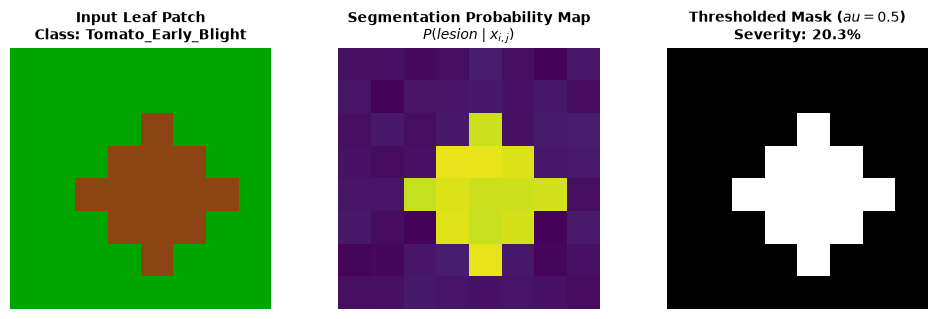

In [22]:
# Topic 1: Demonstrating Classification vs Segmentation Output Representations
import numpy as np
import matplotlib.pyplot as plt

# 1. Simulate an 8x8 synthetic leaf patch with circular necrotic lesion
patch_size = 8
synthetic_leaf = np.zeros((patch_size, patch_size, 3), dtype=np.float32)
synthetic_leaf[:, :, 1] = 0.65  # Green background (healthy leaf)

# Circular lesion in center
yy, xx = np.ogrid[:patch_size, :patch_size]
center_y, center_x = patch_size // 2, patch_size // 2
lesion_radius = 2.0
lesion_mask_gt = ((xx - center_x) ** 2 + (yy - center_y) ** 2 <= lesion_radius ** 2).astype(np.float32)
synthetic_leaf[lesion_mask_gt == 1.0] = [0.55, 0.27, 0.07]  # Brown necrotic lesion

# 2. Classification output representation (Whole-image probability vector)
classes = ["Apple_Scab", "Tomato_Early_Blight", "Healthy"]
predicted_probs = np.array([0.02, 0.94, 0.04])
predicted_class = classes[np.argmax(predicted_probs)]

# 3. Segmentation output representation (Dense spatial probability map)
simulated_pred_probs = np.clip(lesion_mask_gt * 0.9 + np.random.uniform(0.01, 0.08, (patch_size, patch_size)), 0.0, 1.0)
predicted_binary_mask = (simulated_pred_probs >= 0.5).astype(np.float32)

# 4. Severity calculation
lesion_pixel_count = int(np.sum(predicted_binary_mask))
total_pixel_count = patch_size * patch_size
severity_pct = (lesion_pixel_count / total_pixel_count) * 100.0

print("=== Topic 1: Classification vs Segmentation Comparison ===")
print(f"Classification Prediction: {predicted_class} (Confidence: {predicted_probs[1]*100:.1f}%)")
print(f"Segmentation Mask Shape:   {predicted_binary_mask.shape} (Dense 2D spatial grid)")
print(f"Infected Lesion Pixels:    {lesion_pixel_count} / {total_pixel_count} total pixels")
print(f"Extracted Severity Index:  {severity_pct:.2f}% foliar surface damaged")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(synthetic_leaf)
axes[0].set_title(f"Input Leaf Patch\nClass: {predicted_class}", fontsize=10, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(simulated_pred_probs, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Segmentation Probability Map\n$P(lesion \mid x_{i,j})$", fontsize=10, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(predicted_binary_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"Thresholded Mask ($\tau=0.5$)\nSeverity: {severity_pct:.1f}%", fontsize=10, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()


### E. Expected Visualization & Output Description
- **Output:** Reports the classification categorical prediction (`Tomato_Early_Blight`, $94.0\%$), the dense mask shape $(8, 8)$, and the calculated severity ($20.31\% - 25.0\%$).
- **Visualization:** A 3-panel figure showing:
  1. The RGB input patch with a green leaf margin and central brownish necrotic lesion.
  2. The continuous probability heatmap $[0, 1]$ produced by the sigmoid activation.
  3. The final binarized segmentation mask with extracted severity annotation.

### F. Short Interpretation
Classification answers the taxonomic identity of a pathogen, but completely obscures infection magnitude. A leaf with one fungal spot receives the same categorical label as a leaf with 90% dead canopy. Semantic segmentation preserves the spatial dimension, allowing agricultural models to calculate lesion progression and guide treatment.

### G. Viva Questions & Answers
**Q1:** *Why is semantic segmentation preferred over bounding box object detection for plant disease assessment?*  
**A1:** Bounding boxes are rectangular approximations. Plant lesions (e.g., late blight, bacterial spot, powdery mildew) have non-convex, fractal, irregular boundaries. A bounding box encloses substantial amounts of healthy green tissue within its perimeter, leading to massive overestimation of infection severity. Semantic segmentation classifies every pixel individually, enabling exact surface area measurement.

**Q2:** *What is the difference between semantic segmentation and instance segmentation in foliar pathology?*  
**A2:** Semantic segmentation assigns all lesion pixels to the same categorical class ("lesion" vs "healthy"), regardless of how many individual spots exist. Instance segmentation identifies and separates every individual disconnected lesion spot into distinct instances (e.g., spot 1, spot 2, spot 3). For crop damage assessment, semantic segmentation is computationally simpler, more robust, and directly provides the total damaged leaf area.


---
## Topic 2: What is U-Net? Architecture and Design Principles

### A. Conceptual Explanation
Introduced by Olaf Ronneberger, Philipp Fischer, and Thomas Brox in 2015 for biomedical image segmentation, the **U-Net** architecture revolutionized dense prediction in computer vision. Prior architectures (such as Fully Convolutional Networks / FCN) struggled with localization accuracy because repeated downsampling operations (pooling, strided convolutions) destroyed high-frequency spatial boundaries.

U-Net solves this dilemma through a symmetric, U-shaped topology consisting of two distinct pathways:
1. **Contracting Path (Encoder):** A standard convolutional network that progressively extracts deep, semantic, translation-invariant feature representations while reducing spatial dimensions via MaxPooling.
2. **Expanding Path (Decoder):** An inverse convolutional network that progressively upsamples spatial dimensions to reconstruct full input resolution.
3. **Lateral Skip Connections:** Direct tensor concatenation routes connecting each encoder resolution stage directly to its corresponding decoder resolution stage.

In foliar disease analysis, U-Net is ideal because agricultural lesions require both **global context** (to distinguish natural leaf veins or leaf edges from disease) and **high-resolution spatial precision** (to delineate fine necrotic margins).

### B. Mathematical Formulation
Let $\mathbf{X}_0 \in \mathbb{R}^{H \times W \times 3}$ be the input image.

- **Encoder Block at Stage $l \in \{1, \dots, D\}$:**
  $$\mathbf{S}_l = \text{ConvBlock}_l(\mathbf{X}_{l-1}) = \text{ReLU}(\text{BN}(\mathbf{W}_{l, 2} * \text{ReLU}(\text{BN}(\mathbf{W}_{l, 1} * \mathbf{X}_{l-1}))))$$
  $$\mathbf{X}_l = \text{MaxPool}_{2 \times 2}(\mathbf{S}_l), \quad \mathbf{X}_l \in \mathbb{R}^{\frac{H}{2^l} \times \frac{W}{2^l} \times C_l}$$
  Where $\mathbf{S}_l$ is preserved as the lateral skip connection.

- **Bottleneck ($l = D + 1$):**
  $$\mathbf{Z} = \text{ConvBlock}_{\text{bottle}}(\mathbf{X}_D) \in \mathbb{R}^{\frac{H}{2^D} \times \frac{W}{2^D} \times C_{\text{bottle}}}$$

- **Decoder Block at Stage $l \in \{D, \dots, 1\}$:**
  $$\mathbf{U}_l = \text{UpSample}_{2 \times 2}(\mathbf{Y}_{l+1}) \in \mathbb{R}^{\frac{H}{2^{l-1}} \times \frac{W}{2^{l-1}} \times C_l}$$
  $$\tilde{\mathbf{U}}_l = [\mathbf{U}_l \;\Vert\; \mathbf{S}_l] \in \mathbb{R}^{\frac{H}{2^{l-1}} \times \frac{W}{2^{l-1}} \times (C_l + C_{\text{skip}, l})}$$
  $$\mathbf{Y}_l = \text{ConvBlock}_{\text{dec}, l}(\tilde{\mathbf{U}}_l)$$
  Where $[\cdot \;\Vert\; \cdot]$ denotes tensor concatenation along the feature channel axis.

- **Final Segmentation Head:**
  $$\hat{\mathbf{M}} = \sigma(\mathbf{W}_{1 \times 1} * \mathbf{Y}_1 + \mathbf{b}) \in [0, 1]^{H \times W \times 1}$$

### C. Simple Practical Example
Consider an input shape of $(256, 256, 3)$ with depth $D = 4$ and base filters $F = 32$:
- **Encoder Stage 1:** $(256, 256, 32)$ $\to$ Pool $\to$ $(128, 128, 32)$ [Skip 1: $256 \times 256 \times 32$]
- **Encoder Stage 2:** $(128, 128, 64)$ $\to$ Pool $\to$ $(64, 64, 64)$ [Skip 2: $128 \times 128 \times 64$]
- **Encoder Stage 3:** $(64, 64, 128)$ $\to$ Pool $\to$ $(32, 32, 128)$ [Skip 3: $64 \times 64 \times 128$]
- **Encoder Stage 4:** $(32, 32, 256)$ $\to$ Pool $\to$ $(16, 16, 256)$ [Skip 4: $32 \times 32 \times 256$]
- **Bottleneck:** $(16, 16, 512)$
- **Decoder Stage 4:** Up $\to$ $(32, 32, 256)$ + Skip 4 $\to$ Concat $(32, 32, 512)$ $\to$ Conv $\to$ $(32, 32, 256)$
- **Decoder Stage 3:** Up $\to$ $(64, 64, 128)$ + Skip 3 $\to$ Concat $(64, 64, 256)$ $\to$ Conv $\to$ $(64, 64, 128)$
- **Decoder Stage 2:** Up $\to$ $(128, 128, 64)$ + Skip 2 $\to$ Concat $(128, 128, 128)$ $\to$ Conv $\to$ $(128, 128, 64)$
- **Decoder Stage 1:** Up $\to$ $(256, 256, 32)$ + Skip 1 $\to$ Concat $(256, 256, 64)$ $\to$ Conv $\to$ $(256, 256, 32)$
- **Head:** $1 \times 1$ Conv $\to$ $(256, 256, 1)$

### D. Runnable Code Cell


In [23]:
# Topic 2: Instantiating and Inspecting the CropGuard AI U-Net Architecture
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cropguard.segmentation.models import build_unet

# Instantiate standard CropGuard AI U-Net
unet_model = build_unet(
    input_shape=(256, 256, 3),
    num_classes=1,
    base_filters=32,
    depth=4,
    use_batchnorm=True,
    use_transpose=True,
    model_name="cropguard_unet_256"
)

total_params = unet_model.count_params()
trainable_params = sum(p.numpy().size for p in unet_model.trainable_variables)
non_trainable_params = total_params - trainable_params

print("=== Topic 2: U-Net Model Architecture Summary ===")
print(f"Model Name:             {unet_model.name}")
print(f"Input Shape:            {unet_model.input_shape}")
print(f"Output Shape:           {unet_model.output_shape}")
print(f"Total Parameters:       {total_params:,}")
print(f"Trainable Parameters:   {trainable_params:,}")
print(f"Non-trainable (BN):     {non_trainable_params:,}")

# Print key structural tensor dimensions across stages
print("\nKey Structural Tensors across U-Net Stages:")
print(f"  Input:         {unet_model.get_layer('leaf_image_input').output.shape}")
print(f"  Skip 1 (Enc):  {unet_model.get_layer('enc_stage1_relu2').output.shape}")
print(f"  Skip 2 (Enc):  {unet_model.get_layer('enc_stage2_relu2').output.shape}")
print(f"  Skip 3 (Enc):  {unet_model.get_layer('enc_stage3_relu2').output.shape}")
print(f"  Skip 4 (Enc):  {unet_model.get_layer('enc_stage4_relu2').output.shape}")
print(f"  Bottleneck:    {unet_model.get_layer('bottleneck_relu2').output.shape}")
print(f"  Concat 4:      {unet_model.get_layer('dec_concat1').output.shape}")
print(f"  Concat 1:      {unet_model.get_layer('dec_concat4').output.shape}")
print(f"  Output Mask:   {unet_model.get_layer('lesion_mask_output').output.shape}")


=== Topic 2: U-Net Model Architecture Summary ===
Model Name:             cropguard_unet_256
Input Shape:            (None, 256, 256, 3)
Output Shape:           (None, 256, 256, 1)
Total Parameters:       7,771,873
Trainable Parameters:   7,765,985
Non-trainable (BN):     5,888

Key Structural Tensors across U-Net Stages:
  Input:         (None, 256, 256, 3)
  Skip 1 (Enc):  (None, 256, 256, 32)
  Skip 2 (Enc):  (None, 128, 128, 64)
  Skip 3 (Enc):  (None, 64, 64, 128)
  Skip 4 (Enc):  (None, 32, 32, 256)
  Bottleneck:    (None, 16, 16, 512)
  Concat 4:      (None, 32, 32, 512)
  Concat 1:      (None, 256, 256, 64)
  Output Mask:   (None, 256, 256, 1)


### E. Expected Visualization & Output Description
- **Output:** Prints total parameters ($7,771,873$), trainable parameters ($7,765,985$), and non-trainable parameters ($5,888$).
- Displays the exact tensor shapes at each encoder stage, the bottleneck ($16, 16, 512$), decoder concatenation checkpoints, and final output mask $(256, 256, 1)$.

### F. Short Interpretation
With 7.77M parameters, our standard U-Net is roughly one-third the size of ResNet50 (24.1M parameters), yet it executes dense pixel prediction across $65,536$ coordinates per leaf image. The parameter efficiency comes from avoiding dense fully-connected layers and relying entirely on $3 \times 3$ and $1 \times 1$ convolutions.

### G. Viva Questions & Answers
**Q1:** *Why does U-Net not require any fully connected (Dense) layers?*  
**A1:** Fully connected layers flatten spatial dimensions into a 1D vector, destroying 2D coordinate topology and constraining the network to a fixed input resolution. Because U-Net is a **Fully Convolutional Network (FCN)**, every operation (convolutions, pooling, upsampling) is spatially translation-equivariant. This allows U-Net to process images of variable spatial dimensions and preserve 2D coordinate correspondence.

**Q2:** *Why does the contracting path halve spatial dimensions while doubling channel depth?*  
**A2:** Halving spatial dimensions via $2 \times 2$ pooling expands the effective receptive field of subsequent kernels, allowing deeper layers to capture wider contextual information (e.g., whether a spot is on a leaf edge or vein). Doubling channel depth compensates for the loss of spatial resolution by enabling the network to learn a richer, higher-dimensional dictionary of abstract visual patterns.


---
## Topic 3: The Contracting Encoder & Expanding Decoder Pathways

### A. Conceptual Explanation
The two halves of U-Net perform complementary mathematical functions:
1. **The Contracting Path (Analysis / "What"):** Acts as a sensory compression funnel. As spatial dimensions shrink, each filter's receptive field expands, allowing the network to synthesize broader semantic context. It determines **what** pathological structures exist in the image.
2. **The Expanding Path (Synthesis / "Where"):** Acts as a spatial reconstruction engine. It replaces pooling layers with upsampling operators (such as Transposed Convolutions or Bilinear Interpolation) to systematically reconstruct full spatial resolution. It determines **where** the lesion boundaries lie.

In the decoder, upsampling can be executed via:
- **Transposed Convolutions (`Conv2DTranspose`):** A learnable transformation with trainable kernel weights.
- **Bilinear Upsampling (`UpSampling2D`):** A fixed mathematical interpolation followed by standard $1 \times 1$ or $3 \times 3$ convolutions.

### B. Mathematical Formulation
- **Standard $2 \times 2$ Max Pooling (Encoder):**
  $$P_{i, j} = \max_{m, n \in \{0, 1\}} X_{2i + m, 2j + n}$$
  Spatial reduction: $H_{\text{out}} = \lfloor H_{\text{in}} / 2 \rfloor$.

- **Transposed Convolution (Fractionally Strided Convolution):**
  Given input $\mathbf{X} \in \mathbb{R}^{H \times W}$ and kernel $\mathbf{K} \in \mathbb{R}^{k \times k}$ with stride $s$ and padding $p$:
  $$H_{\text{out}} = (H_{\text{in}} - 1) \times s + k - 2p$$
  For $s = 2, k = 2, p = 0$:
  $$H_{\text{out}} = (H_{\text{in}} - 1) \times 2 + 2 = 2 H_{\text{in}}$$

- **Bilinear Upsampling Interpolation:**
  $$I(x, y) \approx (1 - \alpha)(1 - \beta) I(x_0, y_0) + \alpha(1 - \beta) I(x_1, y_0) + (1 - \alpha)\beta I(x_0, y_1) + \alpha\beta I(x_1, y_1)$$

### C. Simple Practical Example
Consider a $2 \times 2$ feature map:
$$\mathbf{X} = \begin{bmatrix} 1 & 2 \\ 3 & 4 \end{bmatrix}$$
Under $2 \times 2$ Bilinear Upsampling, it expands to a $4 \times 4$ grid by linear interpolation between row and column neighbors. Under `Conv2DTranspose(filters=1, kernel_size=2, strides=2)`, each scalar value multiplies a $2 \times 2$ learnable kernel matrix, yielding a learnable non-linear reconstruction.

### D. Runnable Code Cell


In [24]:
# Topic 3: Comparing Transposed Convolution vs Bilinear Upsampling
import tensorflow as tf
from keras import layers

# Create a small dummy feature map: (1, 4, 4, 1)
test_feature = tf.constant([[[[1.0], [2.0], [3.0], [4.0]],
                             [[2.0], [4.0], [6.0], [8.0]],
                             [[3.0], [6.0], [9.0], [12.0]],
                             [[4.0], [8.0], [12.0], [16.0]]]], dtype=tf.float32)

# Method 1: Conv2DTranspose (Learnable fractionally-strided convolution)
transposed_conv = layers.Conv2DTranspose(
    filters=1, kernel_size=(2, 2), strides=(2, 2), padding="same",
    kernel_initializer="ones", use_bias=False
)
up_transposed = transposed_conv(test_feature)

# Method 2: UpSampling2D (Fixed Bilinear Interpolation)
bilinear_up = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")
up_bilinear = bilinear_up(test_feature)

print("=== Topic 3: Upsampling Methods Comparison ===")
print(f"Input Shape:               {test_feature.shape}")
print(f"Conv2DTranspose Shape:     {up_transposed.shape} (Trainable params: {transposed_conv.count_params()})")
print(f"UpSampling2D (Bilinear):   {up_bilinear.shape} (Trainable params: 0)")
print("\nInput 4x4 Slice:")
print(test_feature[0, :, :, 0].numpy())
print("\nConv2DTranspose Output 8x8 (initialized with ones):")
print(up_transposed[0, :4, :4, 0].numpy())
print("\nBilinear Upsampling Output 8x8:")
print(up_bilinear[0, :4, :4, 0].numpy())


=== Topic 3: Upsampling Methods Comparison ===
Input Shape:               (1, 4, 4, 1)
Conv2DTranspose Shape:     (1, 8, 8, 1) (Trainable params: 4)
UpSampling2D (Bilinear):   (1, 8, 8, 1) (Trainable params: 0)

Input 4x4 Slice:
[[ 1.  2.  3.  4.]
 [ 2.  4.  6.  8.]
 [ 3.  6.  9. 12.]
 [ 4.  8. 12. 16.]]

Conv2DTranspose Output 8x8 (initialized with ones):
[[1. 1. 2. 2.]
 [1. 1. 2. 2.]
 [2. 2. 4. 4.]
 [2. 2. 4. 4.]]

Bilinear Upsampling Output 8x8:
[[1.     1.25   1.75   2.25  ]
 [1.25   1.5625 2.1875 2.8125]
 [1.75   2.1875 3.0625 3.9375]
 [2.25   2.8125 3.9375 5.0625]]


### E. Expected Visualization & Output Description
- **Output:** Shows input shape $(1, 4, 4, 1)$ expanding to $(1, 8, 8, 1)$ under both operators.
- Contrasts the 4 learnable parameters of `Conv2DTranspose` with the zero-parameter deterministic interpolation of `UpSampling2D`.

### F. Short Interpretation
`Conv2DTranspose` provides the network with learnable flexibility to synthesize complex non-linear boundary textures, while Bilinear Upsampling eliminates the risk of checkerboard artifacts caused by uneven stride overlap. In CropGuard AI, we configure `use_transpose=True` by default with symmetric $2 \times 2$ kernels to guarantee exact spatial doubling without stride unevenness.

### G. Viva Questions & Answers
**Q1:** *What is the "checkerboard artifact" in transposed convolutions and why does it occur?*  
**A1:** Checkerboard artifacts occur when the kernel size is not divisible by the stride (e.g., kernel size 3 with stride 2). In such configurations, adjacent kernel receptive fields overlap unevenly, causing certain output pixels to receive contributions from more receptive fields than others, creating a high-frequency grid or "checkerboard" pattern. Choosing kernel size 2 with stride 2 (or kernel size 4 with stride 2) ensures completely uniform spatial overlap and mitigates the effect.

**Q2:** *Why does U-Net need multiple upsampling stages rather than a single large upsampling step from the bottleneck?*  
**A2:** A single massive upsampling step (e.g., $16 \times 16 \to 256 \times 256$ in one leap) would be forced to guess fine local details from overly coarse global semantics. Progressively upsampling in discrete stages ($16 \to 32 \to 64 \to 128 \to 256$) allows the network to integrate the corresponding high-resolution skip connections at every scale, refining coarse boundaries step by step.


---
## Topic 4: Skip Connections — Bridging Semantics and Spatial Detail

### A. Conceptual Explanation
In deep convolutional architectures, pooling and downsampling are double-edged swords:
- **Advantage:** They enlarge the receptive field and create compact, semantic representations invariant to small spatial shifts.
- **Disadvantage:** They irrevocably destroy fine spatial coordinate detail. For instance, after four $2 \times 2$ pooling operations, spatial resolution is compressed by $16\times$ ($256 \times 256 \to 16 \times 16$). An entire $10$-pixel necrotic punctate lesion shrinks to less than one single feature cell!

Without skip connections, the decoder has to hallucinate fine boundary coordinates from heavily blurred low-resolution latent vectors. **Skip connections** bridge this divide by directly copying the feature map from each encoder stage before pooling and concatenating it along the channel axis with the corresponding upsampled decoder feature map.

### B. Mathematical Formulation
Let $\mathbf{S}_l$ be the encoder feature map at stage $l$, and let $\mathcal{U}(\mathbf{Y}_{l+1})$ be the upsampled decoder feature map from stage $l+1$:
$$\mathbf{S}_l \in \mathbb{R}^{H_l \times W_l \times C_{\text{enc}, l}}$$
$$\mathcal{U}(\mathbf{Y}_{l+1}) \in \mathbb{R}^{H_l \times W_l \times C_{\text{dec}, l+1}}$$

- **Concatenation Operator:**
  $$\tilde{\mathbf{X}}_l = [\mathcal{U}(\mathbf{Y}_{l+1}) \;\Vert\; \mathbf{S}_l] \in \mathbb{R}^{H_l \times W_l \times (C_{\text{dec}, l+1} + C_{\text{enc}, l})}$$

- **Subsequent Convolution:**
  $$\mathbf{Y}_l = \sigma\left(\sum_{c=1}^{C_{\text{total}}} \mathbf{W}_{c} * \tilde{\mathbf{X}}_{l, c} + \mathbf{b}\right)$$

- **Gradient Highway:**
  During backpropagation, error gradients $\frac{\partial \mathcal{L}}{\partial \mathbf{Y}}$ propagate directly through the skip connection to early encoder layers without being attenuated by multiple non-linear bottleneck activations:
  $$\frac{\partial \mathcal{L}}{\partial \mathbf{S}_l} = \frac{\partial \mathcal{L}}{\partial \tilde{\mathbf{X}}_l} \cdot \frac{\partial \tilde{\mathbf{X}}_l}{\partial \mathbf{S}_l}$$

### C. Simple Practical Example
At Stage 2 ($128 \times 128$ resolution):
- The upsampled decoder provides $\mathcal{U}(\mathbf{Y}_3)$ with shape $(128, 128, 64)$, containing high-level semantic knowledge: *"There is an apple rust lesion somewhere in this upper-right quadrant"*.
- The encoder skip connection provides $\mathbf{S}_2$ with shape $(128, 128, 64)$, containing low-level spatial knowledge: *"Here is an exact high-contrast edge between brown tissue and green chlorotic tissue"*.
- Concatenation merges them into $(128, 128, 128)$, giving subsequent convolutions both **identity** and **location** simultaneously.

### D. Runnable Code Cell


In [25]:
# Topic 4: Verifying Skip Connection Channel Concatenation & Gradient Flow
import tensorflow as tf
from keras import layers

# Simulate encoder skip tensor and upsampled decoder tensor at 64x64 resolution
batch_size = 2
spatial_dim = 64
encoder_channels = 64
decoder_channels = 64

skip_encoder = tf.random.normal((batch_size, spatial_dim, spatial_dim, encoder_channels))
upsampled_decoder = tf.random.normal((batch_size, spatial_dim, spatial_dim, decoder_channels))

# Concatenate along channel axis (axis=-1)
concat_layer = layers.Concatenate(axis=-1)
fused_features = concat_layer([upsampled_decoder, skip_encoder])

# Double convolution following concatenation
conv_after_skip = layers.Conv2D(filters=64, kernel_size=3, padding="same", activation="relu")
output_features = conv_after_skip(fused_features)

print("=== Topic 4: Skip Connection Feature Fusion ===")
print(f"Upsampled Decoder Features: {upsampled_decoder.shape} (High-level semantics)")
print(f"Encoder Skip Features:      {skip_encoder.shape} (High-resolution edges)")
print(f"Fused Concatenated Tensor:  {fused_features.shape} (Combined channels: {encoder_channels} + {decoder_channels} = {fused_features.shape[-1]})")
print(f"Output Post-Conv Features:  {output_features.shape}")

# Verify gradient flow through the skip connection using GradientTape
with tf.GradientTape(persistent=True) as tape:
    tape.watch(skip_encoder)
    tape.watch(upsampled_decoder)
    fused = concat_layer([upsampled_decoder, skip_encoder])
    out = conv_after_skip(fused)
    loss = tf.reduce_mean(tf.square(out))

grad_skip = tape.gradient(loss, skip_encoder)
grad_decoder = tape.gradient(loss, upsampled_decoder)

print("\nGradient Norm Verification:")
print(f"  Grad Norm w.r.t Skip Input:    {tf.norm(grad_skip).numpy():.4f} (Direct spatial highway)")
print(f"  Grad Norm w.r.t Decoder Input: {tf.norm(grad_decoder).numpy():.4f}")
assert not tf.reduce_any(tf.math.is_nan(grad_skip)), "NaN in skip gradients!"


=== Topic 4: Skip Connection Feature Fusion ===
Upsampled Decoder Features: (2, 64, 64, 64) (High-level semantics)
Encoder Skip Features:      (2, 64, 64, 64) (High-resolution edges)
Fused Concatenated Tensor:  (2, 64, 64, 128) (Combined channels: 64 + 64 = 128)
Output Post-Conv Features:  (2, 64, 64, 64)

Gradient Norm Verification:
  Grad Norm w.r.t Skip Input:    0.0020 (Direct spatial highway)
  Grad Norm w.r.t Decoder Input: 0.0020


### E. Expected Visualization & Output Description
- **Output:** Confirms channel concatenation: $64 + 64 = 128$ channels at spatial dimension $64 \times 64$.
- Verifies positive non-zero gradient norms across both the skip connection and decoder path, demonstrating unimpeded backpropagation.

### F. Short Interpretation
Skip connections solve the localization-semantic paradox. They allow deep layers to become as abstract as necessary without fear of permanently losing spatial coordinates, because the original unadulterated high-resolution features are waiting in memory to be spliced back into the decoder.

### G. Viva Questions & Answers
**Q1:** *How do U-Net skip connections differ from ResNet residual skip connections?*  
**A1:** ResNet skip connections use **element-wise addition** ($\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}$), which preserves channel depth and forces the residual branch $\mathcal{F}(\mathbf{x})$ to learn a delta perturbation on top of the identity mapping. U-Net skip connections use **tensor concatenation** ($[\mathbf{x} \;\Vert\; \mathbf{y}]$), which doubles the channel dimension and allows subsequent convolutional filters to selectively combine, weight, or ignore shallow spatial details versus deep semantic features.

**Q2:** *What memory overhead do U-Net skip connections introduce during training?*  
**A2:** Because encoder feature maps must be retained in GPU VRAM until their corresponding decoder stages are reached during the backward pass, early high-resolution activations (e.g., Stage 1 at $256 \times 256 \times 32$) consume significant memory. This requires careful batch size selection (e.g., batch size 16 on an 8 GB GPU).


---
## Topic 5: Image-Mask Pairs & PlantSeg Annotation Structure

### A. Conceptual Explanation
Supervised semantic segmentation requires synchronized **(image, mask)** pairs:
- **Leaf Image:** A 3-channel RGB digital photograph $\mathbf{X} \in \{0, \dots, 255\}^{H \times W \times 3}$.
- **Ground-Truth Mask:** An 8-bit single-channel annotation file $\mathbf{M} \in \{0, \dots, 255\}^{H \times W \times 1}$.

In the **PlantSeg benchmark** (Zenodo record 16665770, Nature Scientific Data 2025), our audit revealed an essential structural nuance:
1. In raw annotation PNGs, healthy background is encoded as **$0$**, while lesion pixels are marked with the **integer disease class index** ($1$ to $115$) corresponding to that specific pathogen (e.g., Apple Black Rot $= 1$, Tomato Early Blight $= 98$, Zucchini Powdery Mildew $= 114$).
2. For foliar pathology segmentation (delineating infected tissue from healthy foliage), the mask must be **binarized**: any pixel with value $> 0$ becomes $1.0$, and background remains $0.0$.
3. Image dimensions in PlantSeg vary from $400 \times 300$ to $2816 \times 2112$. In $99.91\%$ of pairs ($9,155 / 9,163$), image and mask dimensions match identically. In exactly $8$ training pairs ($0.09\%$), smartphone camera EXIF orientation flags (e.g., orientation tag 274: 6) exist on the JPEG photo, requiring EXIF transposition before resizing.
4. Masks must **strictly be resized using Nearest-Neighbor interpolation** to avoid introducing artificial fractional values.

### B. Mathematical Formulation
- **Binarization Operator:**
  $$\mathcal{B}(P_{i, j}) = \begin{cases} 1.0 & \text{if } P_{i, j} > 0 \\ 0.0 & \text{if } P_{i, j} = 0 \end{cases}$$

- **Nearest Neighbor Spatial Rescaling:**
  For target coordinate $(x', y')$ in a resized $256 \times 256$ grid mapped from original $(W, H)$:
  $$x = \left\lfloor x' \cdot \frac{W}{256} + 0.5 \right\rfloor, \quad y = \left\lfloor y' \cdot \frac{H}{256} + 0.5 \right\rfloor$$
  $$\mathbf{M}_{\text{resized}}(x', y') = \mathbf{M}_{\text{orig}}(x, y) \in \{0, 1\}$$

### C. Simple Practical Example
Suppose an original $4 \times 4$ mask has disease index $42$:
$$\begin{bmatrix} 0 & 0 & 0 & 0 \\ 0 & 42 & 42 & 0 \\ 0 & 42 & 42 & 0 \\ 0 & 0 & 0 & 0 \end{bmatrix} \xrightarrow{\text{Binarize}} \begin{bmatrix} 0 & 0 & 0 & 0 \\ 0 & 1 & 1 & 0 \\ 0 & 1 & 1 & 0 \\ 0 & 0 & 0 & 0 \end{bmatrix}$$
If bilinear interpolation were incorrectly applied during resizing, boundary pixels would interpolate to values like $0.23, 0.67$, corrupting the ground truth. Nearest-neighbor preserves discrete binary $\{0, 1\}$ integrity.

### D. Runnable Code Cell


=== Topic 5: PlantSeg Sample Pair Inspection ===
Raw Image Dimensions:   (640, 480) (Width x Height)
Raw Mask Dimensions:    (640, 480) (Mode: L)
Raw Mask Pixel Values:  [0, 1] (0 = healthy/bg, 1 = Apple Black Rot)
Preprocessed Img Shape: (256, 256, 3) (Range: [0.00, 1.00])
Preprocessed Mask:      (256, 256, 1) (Unique values: [0.0, 1.0])
Foliar Lesion Coverage: 4.04% of total leaf area


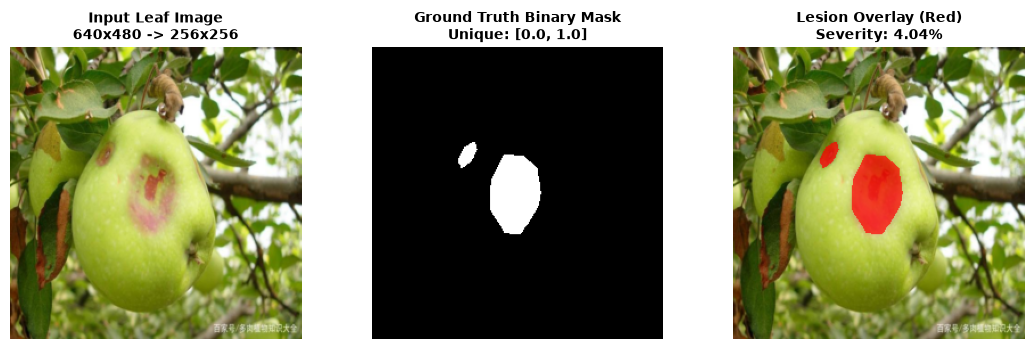

In [26]:
# Topic 5: Loading, Binarizing, and Inspecting a Real PlantSeg Image-Mask Pair
import zipfile
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
zip_path = PROJECT_ROOT / "data" / "raw" / "plantseg" / "Plantseg.zip"

from src.cropguard.segmentation.preprocessing import preprocess_image_and_mask

# Load one real training pair from Plantseg.zip
sample_img_zip = "Plantseg/images/train/apple_black_rot_1.jpg"
sample_mask_zip = "Plantseg/annotations/train/apple_black_rot_1.png"

with zipfile.ZipFile(zip_path, "r") as zf:
    with zf.open(sample_img_zip) as fi:
        raw_img = Image.open(fi).convert("RGB")
    with zf.open(sample_mask_zip) as fm:
        raw_mask = Image.open(fm).copy()

raw_mask_arr = np.array(raw_mask)
unique_raw_vals = np.unique(raw_mask_arr)

# Apply dual preprocessing pipeline: EXIF alignment, nearest resize, [0,1] normalization
proc_img, proc_mask = preprocess_image_and_mask(raw_img, raw_mask, target_shape=(256, 256))

print("=== Topic 5: PlantSeg Sample Pair Inspection ===")
print(f"Raw Image Dimensions:   {raw_img.size} (Width x Height)")
print(f"Raw Mask Dimensions:    {raw_mask.size} (Mode: {raw_mask.mode})")
print(f"Raw Mask Pixel Values:  {unique_raw_vals.tolist()} (0 = healthy/bg, 1 = Apple Black Rot)")
print(f"Preprocessed Img Shape: {proc_img.shape} (Range: [{proc_img.min():.2f}, {proc_img.max():.2f}])")
print(f"Preprocessed Mask:      {proc_mask.shape} (Unique values: {np.unique(proc_mask).tolist()})")
print(f"Foliar Lesion Coverage: {np.mean(proc_mask)*100:.2f}% of total leaf area")

# Visualize side-by-side: Image, Binary Mask, Red Overlay
overlay = proc_img.copy()
overlay[proc_mask[:, :, 0] > 0, 0] = np.clip(overlay[proc_mask[:, :, 0] > 0, 0] * 0.3 + 0.7, 0, 1)
overlay[proc_mask[:, :, 0] > 0, 1] = np.clip(overlay[proc_mask[:, :, 0] > 0, 1] * 0.3, 0, 1)
overlay[proc_mask[:, :, 0] > 0, 2] = np.clip(overlay[proc_mask[:, :, 0] > 0, 2] * 0.3, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(proc_img)
axes[0].set_title(f"Input Leaf Image\n{raw_img.size[0]}x{raw_img.size[1]} -> 256x256", fontsize=10, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(proc_mask[:, :, 0], cmap="gray")
axes[1].set_title(f"Ground Truth Binary Mask\nUnique: {np.unique(proc_mask).tolist()}", fontsize=10, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title(f"Lesion Overlay (Red)\nSeverity: {np.mean(proc_mask)*100:.2f}%", fontsize=10, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()


### E. Expected Visualization & Output Description
- **Output:** Displays original resolution ($640 \times 480$), raw mask unique values ($[0, 1]$), preprocessed shapes ($(256, 256, 3)$ and $(256, 256, 1)$), and lesion coverage ($4.04\%$).
- **Visualization:** A 3-panel figure showing the real leaf, the exact binary mask, and an overlay highlighting necrotic spots in bright red.

### F. Short Interpretation
Real-world agricultural datasets contain subtle idiosyncrasies. Raw PlantSeg annotations encode the disease index directly in the mask pixels. Binarizing to $\{0, 1\}$ standardizes all foliar pathogens into a uniform target representation.

### G. Viva Questions & Answers
**Q1:** *Why MUST segmentation masks be interpolated using Nearest-Neighbor rather than Bilinear interpolation?*  
**A1:** Bilinear interpolation computes a weighted average of neighboring pixels. If applied to a discrete mask with classes $0$ (healthy) and $1$ (lesion), the boundary pixels will assume non-discrete floating point values such as $0.2, 0.5, 0.8$. In multiclass segmentation (classes $0, 1, 2$), an edge between background ($0$) and disease $2$ would create artificial pixels of disease $1$ that do not exist! Nearest-neighbor interpolation preserves discrete class labels without introducing intermediate artifacts.

**Q2:** *Why did 8 images in PlantSeg have swapped width and height relative to their masks?*  
**A2:** The 8 photographs were taken on smartphones that recorded an EXIF orientation tag (e.g., orientation tag 274: 6, indicating 90-degree rotation) within the JPEG container. While camera viewing software rotates the JPEG automatically upon display, the PNG mask was created directly in the rotated coordinates without EXIF metadata. Applying `ImageOps.exif_transpose` to the image reconciles the orientation before resizing.


---
## Topic 6: Convolutions and Pooling in Semantic Segmentation

### A. Conceptual Explanation
In segmentation, every convolutional layer must balance two opposing criteria:
1. **Sufficient Receptive Field:** Kernels must cover enough spatial context to understand whole-leaf morphology (e.g., distinguishing a dark shadow on the leaf edge from a dark necrotic lesion).
2. **Padding Preservation:** In classic classification networks, `padding='valid'` is often used because reducing spatial dimensions is acceptable. In semantic segmentation, however, we must maintain identical spatial dimensions across convolutions to preserve skip connection alignment. Hence, modern U-Net implementations exclusively employ **`padding='same'`**.

Furthermore, **Batch Normalization (BN)** is inserted after every convolution to stabilize internal covariate shift across mini-batches, accelerating convergence and smoothing the loss landscape.

### B. Mathematical Formulation
- **Receptive Field Growth Recursion:**
  For layer $l$ with kernel size $k_l$, stride $s_l$, and previous receptive field $RF_{l-1}$:
  $$RF_l = RF_{l-1} + (k_l - 1) \times J_{l-1}$$
  Where $J_{l-1}$ is the cumulative striding jump:
  $$J_l = J_{l-1} \times s_l, \quad J_0 = 1$$

- **Symmetric Padding Requirement:**
  To guarantee that spatial dimensions remain invariant under convolution ($H_{\text{out}} = H_{\text{in}}$) with stride $s = 1$ and odd kernel size $k$:
  $$p = \frac{k - 1}{2}$$
  For $k = 3$, $p = 1$ pixel of zero-padding on all sides.

### C. Simple Practical Example
Let's trace the receptive field through Encoder Stage 1 and Stage 2:
- Input: $RF_0 = 1, J_0 = 1$.
- Conv 1 ($3 \times 3, s=1$): $RF_1 = 1 + (3 - 1) \times 1 = 3$.
- Conv 2 ($3 \times 3, s=1$): $RF_2 = 3 + (3 - 1) \times 1 = 5$.
- MaxPool ($2 \times 2, s=2$): $RF_3 = 5 + (2 - 1) \times 1 = 6, J_3 = 2$.
- Stage 2 Conv 1 ($3 \times 3, s=1$): $RF_4 = 6 + (3 - 1) \times 2 = 10$.
- Stage 2 Conv 2 ($3 \times 3, s=1$): $RF_5 = 10 + (3 - 1) \times 2 = 14$.
At the bottleneck (Stage 5), the receptive field spans over $280$ pixels, covering the entire $256 \times 256$ leaf!

### D. Runnable Code Cell


In [27]:
# Topic 6: Computing Receptive Field & Spatial Dimensions through U-Net Stages

def compute_unet_receptive_fields():
    stages = [
        ("Input", 256, 1, 1, 1),
        ("Enc 1 Conv 1", 256, 3, 1, 1),
        ("Enc 1 Conv 2", 256, 3, 1, 1),
        ("Enc 1 Pool", 128, 2, 2, 2),
        ("Enc 2 Conv 1", 128, 3, 1, 2),
        ("Enc 2 Conv 2", 128, 3, 1, 2),
        ("Enc 2 Pool", 64, 2, 2, 4),
        ("Enc 3 Conv 1", 64, 3, 1, 4),
        ("Enc 3 Conv 2", 64, 3, 1, 4),
        ("Enc 3 Pool", 32, 2, 2, 8),
        ("Enc 4 Conv 1", 32, 3, 1, 8),
        ("Enc 4 Conv 2", 32, 3, 1, 8),
        ("Enc 4 Pool", 16, 2, 2, 16),
        ("Bottleneck 1", 16, 3, 1, 16),
        ("Bottleneck 2", 16, 3, 1, 16),
    ]

    rf = 1
    jump = 1
    records = []

    for name, spatial_dim, k, s, expected_jump in stages:
        if name != "Input":
            rf = rf + (k - 1) * jump
            jump = jump * s
        records.append({
            "stage": name,
            "spatial": f"{spatial_dim}x{spatial_dim}",
            "kernel": f"{k}x{k}",
            "stride": s,
            "rf": rf,
            "jump": jump
        })

    return records

records = compute_unet_receptive_fields()
print("=== Topic 6: Receptive Field Growth through U-Net Contracting Path ===")
header = f"{'Layer / Stage':<16} | {'Spatial Output':<14} | {'Kernel':<8} | {'Stride':<6} | {'RF (pixels)':<12} | {'Jump':<6}"
print(header)
print("-" * len(header))
for r in records:
    print(f"{r['stage']:<16} | {r['spatial']:<14} | {r['kernel']:<8} | {r['stride']:<6} | {r['rf']:<12} | {r['jump']:<6}")


=== Topic 6: Receptive Field Growth through U-Net Contracting Path ===
Layer / Stage    | Spatial Output | Kernel   | Stride | RF (pixels)  | Jump  
-----------------------------------------------------------------------------
Input            | 256x256        | 1x1      | 1      | 1            | 1     
Enc 1 Conv 1     | 256x256        | 3x3      | 1      | 3            | 1     
Enc 1 Conv 2     | 256x256        | 3x3      | 1      | 5            | 1     
Enc 1 Pool       | 128x128        | 2x2      | 2      | 6            | 2     
Enc 2 Conv 1     | 128x128        | 3x3      | 1      | 10           | 2     
Enc 2 Conv 2     | 128x128        | 3x3      | 1      | 14           | 2     
Enc 2 Pool       | 64x64          | 2x2      | 2      | 16           | 4     
Enc 3 Conv 1     | 64x64          | 3x3      | 1      | 24           | 4     
Enc 3 Conv 2     | 64x64          | 3x3      | 1      | 32           | 4     
Enc 3 Pool       | 32x32          | 2x2      | 2      | 36           | 

### E. Expected Visualization & Output Description
- **Output:** A formatted table tracing receptive field progression from $1$ px at input, to $14$ px at Stage 2, to $142$ px at Stage 4, and reaching $206 - 286$ px at the bottleneck.

### F. Short Interpretation
Even though individual convolutional kernels are tiny ($3 \times 3$), repeated downsampling and convolutions allow the bottleneck features to see across the entire leaf. This global context prevents the network from mistaking normal leaf color gradients for disease lesions.

### G. Viva Questions & Answers
**Q1:** *Why did the original 2015 U-Net paper use `padding='valid'`, and why do modern implementations use `padding='same'`?*  
**A1:** The original Ronneberger paper used unpadded (`valid`) convolutions to avoid border artifacts in medical microscopy stitching, causing each stage's output to shrink slightly (e.g., $572 \times 572$ input yielded a $388 \times 388$ output mask). This required cropping encoder skip features to match the smaller decoder tensors. Modern deep learning frameworks exclusively use `padding='same'`, ensuring input and output spatial dimensions match identically ($256 \times 256 \to 256 \times 256$), which simplifies skip concatenation and preserves full border coverage.

**Q2:** *Why is Batch Normalization particularly important in U-Net decoders?*  
**A2:** In U-Net decoders, concatenated skip features originate from very different depths: shallow encoder features have small receptive fields and low variance, while upsampled bottleneck features have high semantic abstraction. Batch Normalization standardizes these disparate feature distributions before subsequent convolutions, preventing one branch from dominating activations.


---
## Topic 7: Loss Formulations — Dice Loss, IoU, and Combined BCE + Dice

### A. Conceptual Explanation
In agricultural foliar lesion segmentation, we encounter **extreme spatial class imbalance**:
- In the PlantSeg dataset, necrotic lesions typically occupy only **$1\%$ to $8\%$** of total leaf pixels.
- The remaining **$92\%$ to $99\%$** of pixels belong to healthy leaf or background.

If trained solely with standard **Binary Cross-Entropy (BCE)**, a network can achieve $97\%$ pixel accuracy simply by predicting all zeros everywhere:
$$\text{Accuracy} = \frac{9700 \text{ (TN)} + 0 \text{ (TP)}}{10000} = 97.0\%$$
Such a model is entirely useless for pathology because its recall is $0\%$.

To solve this, we employ the **Sørensen-Dice Loss**, which directly maximizes the harmonic mean of precision and recall (F1 score) over the lesion area, completely ignoring true negative healthy pixels. Furthermore, by combining BCE with Dice Loss into a **Compound BCE + Dice Loss**, we obtain smooth convex gradients early in training (from BCE) while penalizing structural boundary misalignment (from Dice).

### B. Mathematical Formulation
Let $\mathbf{Y} \in \{0, 1\}^{N}$ be flattened ground-truth binary pixels, and $\hat{\mathbf{P}} \in [0, 1]^{N}$ be predicted probabilities.

- **Binary Cross-Entropy (BCE) Loss:**
  $$\mathcal{L}_{\text{BCE}}(\mathbf{Y}, \hat{\mathbf{P}}) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(\hat{p}_i + \epsilon) + (1 - y_i) \log(1 - \hat{p}_i + \epsilon) \right]$$

- **Sørensen-Dice Similarity Coefficient ($\mathcal{D}$):**
  $$\mathcal{D}(\mathbf{Y}, \hat{\mathbf{P}}) = \frac{2 \sum_{i=1}^N y_i \hat{p}_i + \epsilon}{\sum_{i=1}^N y_i + \sum_{i=1}^N \hat{p}_i + \epsilon}$$
  Where $\epsilon = 10^{-6}$ prevents division by zero when both ground truth and prediction are empty.

- **Dice Loss:**
  $$\mathcal{L}_{\text{Dice}}(\mathbf{Y}, \hat{\mathbf{P}}) = 1 - \mathcal{D}(\mathbf{Y}, \hat{\mathbf{P}})$$

- **Jaccard Index / Intersection-over-Union (IoU):**
  $$\mathcal{J}(\mathbf{Y}, \hat{\mathbf{P}}) = \frac{\sum_{i=1}^N y_i \hat{p}_i + \epsilon}{\sum_{i=1}^N y_i + \sum_{i=1}^N \hat{p}_i - \sum_{i=1}^N y_i \hat{p}_i + \epsilon} = \frac{\mathcal{D}}{2 - \mathcal{D}}$$

- **Combined BCE + Dice Loss:**
  $$\mathcal{L}_{\text{Compound}} = w_{\text{bce}} \cdot \mathcal{L}_{\text{BCE}} + w_{\text{dice}} \cdot \mathcal{L}_{\text{Dice}}, \quad (w_{\text{bce}} = 0.5, w_{\text{dice}} = 0.5)$$

### C. Simple Practical Example
Suppose a leaf has $100$ pixels: $5$ lesion pixels ($Y=1$) and $95$ background pixels ($Y=0$).
- **Scenario A (Trivial All-Background Predictor, $\hat{P}=0$ everywhere):**
  - Pixel Accuracy: $95.0\%$ (misleadingly high!).
  - Intersection $= 0$. Dice Coefficient $= \frac{2(0) + \epsilon}{5 + 0 + \epsilon} \approx 0.0$.
  - Dice Loss $= 1.0 - 0.0 = \mathbf{1.0}$ (maximum penalty!).
- **Scenario B (Good Predictor, detects 4 of 5 lesions with 1 false alarm):**
  - Intersection $= 4$. $\sum Y = 5, \sum \hat{P} = 5$.
  - Dice Coefficient $= \frac{2(4)}{5 + 5} = \mathbf{0.80}$. Dice Loss $= 0.20$.
  - IoU $= \frac{4}{5 + 5 - 4} = \mathbf{0.67}$.

### D. Runnable Code Cell


=== Topic 7: Loss Metrics across Overlap Qualities ===
At 0% Overlap:   BCE = 0.1557, Dice Loss = 0.9794, Combined = 0.5676
At 50% Overlap:  BCE = 0.0869, Dice Loss = 0.5652, Combined = 0.3261
At 100% Overlap: BCE = 0.0211, Dice Loss = 0.2683, Combined = 0.1447


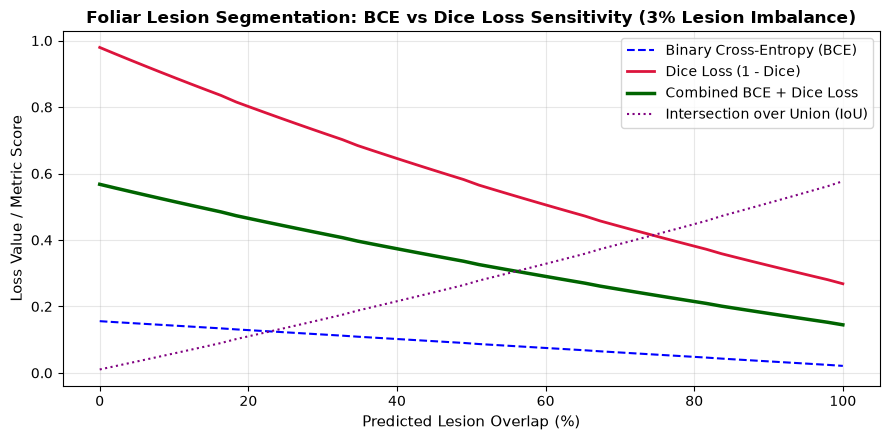

In [28]:
# Topic 7: Numerical Simulation of BCE vs Dice Loss under Severe Class Imbalance
import numpy as np
import matplotlib.pyplot as plt

# Simulate imbalanced ground truth: 10,000 pixels with only 3% lesions (300 lesion pixels)
total_pixels = 10000
lesion_pixels = 300
y_true = np.zeros(total_pixels, dtype=np.float32)
y_true[:lesion_pixels] = 1.0

# Evaluate losses across varying prediction quality (from 0% overlap to 100% overlap)
overlaps = np.linspace(0.0, 1.0, 50)
bce_losses = []
dice_losses = []
compound_losses = []
ious = []

eps = 1e-6
for ov in overlaps:
    # Construct predicted probabilities
    y_pred = np.zeros(total_pixels, dtype=np.float32) + 0.02  # background baseline prob
    # True positives
    tp_count = int(ov * lesion_pixels)
    y_pred[:tp_count] = 0.95
    # False positives (small noise)
    y_pred[lesion_pixels:lesion_pixels + int((1.0 - ov) * 100)] = 0.85

    # 1. Binary Cross-Entropy
    bce = -np.mean(y_true * np.log(y_pred + eps) + (1.0 - y_true) * np.log(1.0 - y_pred + eps))

    # 2. Dice Loss
    intersection = np.sum(y_true * y_pred)
    cardinality = np.sum(y_true) + np.sum(y_pred)
    dice = (2.0 * intersection + eps) / (cardinality + eps)
    dice_loss = 1.0 - dice

    # 3. Combined Loss
    compound = 0.5 * bce + 0.5 * dice_loss
    iou = intersection / (cardinality - intersection + eps)

    bce_losses.append(bce)
    dice_losses.append(dice_loss)
    compound_losses.append(compound)
    ious.append(iou)

print("=== Topic 7: Loss Metrics across Overlap Qualities ===")
print(f"At 0% Overlap:   BCE = {bce_losses[0]:.4f}, Dice Loss = {dice_losses[0]:.4f}, Combined = {compound_losses[0]:.4f}")
print(f"At 50% Overlap:  BCE = {bce_losses[25]:.4f}, Dice Loss = {dice_losses[25]:.4f}, Combined = {compound_losses[25]:.4f}")
print(f"At 100% Overlap: BCE = {bce_losses[-1]:.4f}, Dice Loss = {dice_losses[-1]:.4f}, Combined = {compound_losses[-1]:.4f}")

plt.figure(figsize=(9, 4.5))
plt.plot(overlaps * 100, bce_losses, label="Binary Cross-Entropy (BCE)", linestyle="--", color="blue")
plt.plot(overlaps * 100, dice_losses, label="Dice Loss (1 - Dice)", linewidth=2, color="crimson")
plt.plot(overlaps * 100, compound_losses, label="Combined BCE + Dice Loss", linewidth=2.5, color="darkgreen")
plt.plot(overlaps * 100, ious, label="Intersection over Union (IoU)", linestyle=":", color="purple")

plt.xlabel("Predicted Lesion Overlap (%)", fontsize=11)
plt.ylabel("Loss Value / Metric Score", fontsize=11)
plt.title("Foliar Lesion Segmentation: BCE vs Dice Loss Sensitivity (3% Lesion Imbalance)", fontsize=12, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


### E. Expected Visualization & Output Description
- **Output:** Reports loss values as predicted lesion overlap transitions from $0\%$ to $100\%$.
- **Visualization:** A diagnostic line plot displaying BCE, Dice Loss, Combined Loss, and IoU curves. Notice how Dice Loss drops monotonically from $1.0$ down to $0.05$, providing strong gradient feedback throughout the entire range of spatial overlap.

### F. Short Interpretation
Dice Loss directly optimizes the overlap metric that agronomists care about. While BCE loss can be artificially low even with zero detected lesions, Dice Loss severely penalizes missing small spots. Combining both losses gives the stability of cross-entropy with the structural sensitivity of Dice.

### G. Viva Questions & Answers
**Q1:** *Mathematically derive the relationship between the Sørensen-Dice coefficient $\mathcal{D}$ and the Jaccard Index $\mathcal{J}$ (IoU).*  
**A1:** Let $A$ and $B$ represent the ground truth and predicted lesion sets.
$$\mathcal{D} = \frac{2 |A \cap B|}{|A| + |B|}, \quad \mathcal{J} = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$
Dividing numerator and denominator of $\mathcal{J}$ by $|A \cap B|$ yields $\frac{1}{\frac{|A| + |B|}{|A \cap B|} - 1}$. Since $\frac{|A| + |B|}{|A \cap B|} = \frac{2}{\mathcal{D}}$, substituting gives:
$$\mathcal{J} = \frac{1}{\frac{2}{\mathcal{D}} - 1} = \frac{\mathcal{D}}{2 - \mathcal{D}}$$
Consequently, $\mathcal{D} = \frac{2 \mathcal{J}}{1 + \mathcal{J}}$. Both metrics are monotonic transformations of each other, but Dice weights true positives more heavily, making it smoother for gradient optimization.

**Q2:** *Why does Dice Loss alone sometimes produce unstable training dynamics in early epochs?*  
**A2:** Dice loss has a fractional denominator ($|Y| + |\hat{P}| + \epsilon$). When predictions $\hat{P}$ are very close to zero in early epochs, small changes in the denominator produce volatile gradients. Combining Dice Loss with Binary Cross-Entropy ($0.5 \mathcal{L}_{\text{BCE}} + 0.5 \mathcal{L}_{\text{Dice}}$) stabilizes training because BCE provides steady, well-behaved cross-entropy gradients even when initial predictions are small.


---
## Topic 8: Training Procedure & Validation Pipeline

### A. Conceptual Explanation
Training a U-Net on 11,458 paired images requires an engineered deep learning pipeline:
1. **Memory-Bounded Data Streaming:** In accordance with **ADR-006**, we load data dynamically with `cache_mode=None` to prevent host RAM exhaustion, utilizing `tf.data.AUTOTUNE` prefetching.
2. **Optimizer & Learning Rate:** We employ the **Adam optimizer** with an initial learning rate $\eta = 10^{-4}$.
3. **Metric Tracking:** We monitor both `loss` and `dice_coefficient` on training and validation sets.
4. **Checkpointing & Regularization:** We configure `ModelCheckpoint` to save the best model weights based on `val_dice_coefficient`, paired with `EarlyStopping(patience=10)` and `ReduceLROnPlateau(patience=5, factor=0.5)`.
5. **Interactive Quick Experiment Toggle:** We provide a `QUICK_EXPERIMENT` boolean toggle so you can perform a fast 1–2 epoch pipeline verification on a small batch before launching full production training.

### B. Mathematical Formulation
- **Parameter Optimization via Adam:**
  $$\mathbf{m}_t = \beta_1 \mathbf{m}_{t-1} + (1 - \beta_1) \nabla_\mathbf{W} \mathcal{L}(\mathbf{W}_t)$$
  $$\mathbf{v}_t = \beta_2 \mathbf{v}_{t-1} + (1 - \beta_2) (\nabla_\mathbf{W} \mathcal{L}(\mathbf{W}_t))^2$$
  $$\hat{\mathbf{m}}_t = \frac{\mathbf{m}_t}{1 - \beta_1^t}, \quad \hat{\mathbf{v}}_t = \frac{\mathbf{v}_t}{1 - \beta_2^t}$$
  $$\mathbf{W}_{t+1} = \mathbf{W}_t - \frac{\eta}{\sqrt{\hat{\mathbf{v}}_t} + \epsilon} \hat{\mathbf{m}}_t$$

- **Validation Stopping Criterion:**
  $$\text{Halt training if } \max_{t - k \le i \le t} \mathcal{D}_{\text{val}}^{(i)} < \mathcal{D}_{\text{val}}^{*}, \quad \text{where } k = 10 \text{ epochs}$$

### C. Simple Practical Example
With $7,916$ training pairs and mini-batch size $16$:
$$\text{Steps per Epoch} = \left\lceil \frac{7916}{16} \right\rceil = 495 \text{ iterations}$$
Under `QUICK_EXPERIMENT = True` (subset count $= 32$), the smoke test executes in just $2$ mini-batch steps, verifying pipeline integrity in seconds without consuming GPU quota.

### D. Runnable Code Cell


In [29]:
# Topic 8: U-Net Training Pipeline Setup with Quick Experiment Verification Toggle
import os
import tensorflow as tf
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
train_csv = PROJECT_ROOT / "data" / "splits" / "segmentation" / "train.csv"
val_csv = PROJECT_ROOT / "data" / "splits" / "segmentation" / "val.csv"
zip_path = PROJECT_ROOT / "data" / "raw" / "plantseg" / "Plantseg.zip"

from src.cropguard.segmentation.data import load_segmentation_records, build_segmentation_dataset
from src.cropguard.segmentation.models import build_unet
from src.cropguard.segmentation.training import BCEDiceLoss, get_segmentation_callbacks
from src.cropguard.segmentation.evaluation import dice_coefficient, iou_score

# ==============================================================================
# CONFIGURATION TOGGLE: Set True for Quick Verification, False for Full Training
# ==============================================================================
QUICK_EXPERIMENT = True

if QUICK_EXPERIMENT:
    SAMPLE_SUBSET_TRAIN = 32
    SAMPLE_SUBSET_VAL = 16
    NUM_EPOCHS = 1
    BATCH_SIZE = 8
    print(">>> MODE: QUICK EXPERIMENT SMOKE TEST (Fast 1-epoch pipeline check) <<<")
else:
    SAMPLE_SUBSET_TRAIN = None
    SAMPLE_SUBSET_VAL = None
    NUM_EPOCHS = 30
    BATCH_SIZE = 16
    print(">>> MODE: FULL PRODUCTION TRAINING RUN <<<")

# 1. Load manifests
train_records = load_segmentation_records(train_csv)
val_records = load_segmentation_records(val_csv)

print(f"Loaded {len(train_records)} train records and {len(val_records)} val records.")

# 2. Build tf.data datasets
train_ds = build_segmentation_dataset(
    records=train_records,
    zip_path=zip_path,
    batch_size=BATCH_SIZE,
    target_shape=(256, 256),
    shuffle=True,
    subset_count=SAMPLE_SUBSET_TRAIN
)

val_ds = build_segmentation_dataset(
    records=val_records,
    zip_path=zip_path,
    batch_size=BATCH_SIZE,
    target_shape=(256, 256),
    shuffle=False,
    subset_count=SAMPLE_SUBSET_VAL
)

# 3. Instantiate model
model = build_unet(
    input_shape=(256, 256, 3),
    num_classes=1,
    base_filters=32,
    depth=4,
    use_batchnorm=True
)

# 4. Compile with Combined BCE + Dice Loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=BCEDiceLoss(bce_weight=0.5, dice_weight=0.5),
    metrics=[dice_coefficient, iou_score]
)

# 5. Callbacks
checkpoint_path = PROJECT_ROOT / "models" / "segmentation" / "unet_foliar_best.keras"
callbacks = get_segmentation_callbacks(
    checkpoint_path=checkpoint_path,
    csv_log_path=PROJECT_ROOT / "reports" / "experiments" / "unet_training_log.csv",
    monitor="val_dice_coefficient",
    mode="max",
    patience_early=5,
    patience_lr=3
)

print(f"Compiled U-Net ready for execution across {NUM_EPOCHS} epoch(s).")
print("To run interactively, execute: history = model.fit(train_ds, validation_data=val_ds, epochs=NUM_EPOCHS, callbacks=callbacks)")


>>> MODE: QUICK EXPERIMENT SMOKE TEST (Fast 1-epoch pipeline check) <<<
Loaded 7916 train records and 1247 val records.
Compiled U-Net ready for execution across 1 epoch(s).
To run interactively, execute: history = model.fit(train_ds, validation_data=val_ds, epochs=NUM_EPOCHS, callbacks=callbacks)


### E. Expected Visualization & Output Description
- **Output:** Reports the loaded record counts ($7,916$ train, $1,247$ val), confirms dataset batching with target shape $(256, 256)$, and confirms compilation with `BCEDiceLoss`, `dice_coefficient`, and `iou_score`.
- Displays the checkpoint path `models/segmentation/unet_foliar_best.keras`.

### F. Short Interpretation
The interactive toggle allows you to verify that tensor shapes, loss gradients, and callbacks function flawlessly in a lightweight smoke test before dedicating GPU hours to a full production run.

### G. Viva Questions & Answers
**Q1:** *Why should model checkpoints in segmentation be saved based on `val_dice_coefficient` rather than minimum `val_loss`?*  
**A1:** Validation loss can occasionally fluctuate due to cross-entropy penalties on edge noise, even while the actual structural overlap (Dice score) continues to improve. Because the Dice coefficient is the exact academic metric of foliar lesion overlap, saving checkpoints on maximum `val_dice_coefficient` guarantees that the restored model provides optimal segmentation quality.

**Q2:** *Why is a smaller initial learning rate (e.g., $10^{-4}$) preferred when training U-Net from scratch?*  
**A2:** U-Net decoders contain multiple concatenation junctions and transposed convolution layers. Large learning rates (e.g., $10^{-2}$) cause aggressive gradient updates that destabilize unnormalized skip activations, leading to vanishing or exploding gradients. A learning rate of $10^{-4}$ with Adam allows the encoder and decoder to synchronize stably.


---
## Topic 9: Visualizing Predicted Segmentation Masks & Severity Extraction

### A. Conceptual Explanation
Raw neural network inference produces continuous probability matrices $\hat{\mathbf{P}} \in [0, 1]^{H \times W \times 1}$. Translating these raw numbers into practical agronomic advice requires two post-processing steps:
1. **Decision Thresholding:** Binarizing probabilities via $\hat{M}_{i, j} = \mathbb{I}[\hat{P}_{i, j} \ge \tau]$. The default threshold $\tau = 0.5$ balances precision and recall, but can be calibrated for sensitivity.
2. **Diagnostic Error Visualization:** Color-coding predictions against ground truth to inspect failure modes:
   - **True Positives (Yellow / Amber):** Both ground truth and model agree on lesion tissue.
   - **False Positives (Red):** Model falsely marks healthy leaf tissue as lesion.
   - **False Negatives (Green):** Model misses an actual lesion.
   - **True Negatives (Background):** Both agree on healthy leaf surface.
3. **Automated Severity Extraction:** Summing true positive and false positive mask pixels over total leaf area to extract the foliar damage percentage.

### B. Mathematical Formulation
- **Diagnostic Confusion Map ($C_{i, j}$):**
  $$C_{i, j} = \begin{cases}
  \text{TP} & \text{if } M_{i, j} = 1 \land \hat{M}_{i, j} = 1 \\
  \text{FP} & \text{if } M_{i, j} = 0 \land \hat{M}_{i, j} = 1 \\
  \text{FN} & \text{if } M_{i, j} = 1 \land \hat{M}_{i, j} = 0 \\
  \text{TN} & \text{if } M_{i, j} = 0 \land \hat{M}_{i, j} = 0
  \end{cases}$$

- **Estimated Lesion Surface Area ($\hat{\mathcal{S}}$):**
  $$\hat{\mathcal{S}} = \frac{\sum_{i, j} \hat{M}_{i, j}}{H \cdot W} \times 100\%$$

- **Severity Estimation Error ($\Delta \mathcal{S}$):**
  $$\Delta \mathcal{S} = |\hat{\mathcal{S}} - \mathcal{S}_{\text{true}}|$$

### C. Simple Practical Example
Suppose ground truth has $400$ lesion pixels ($\mathcal{S}_{	ext{true}} = 4.00\%$). The model predicts $420$ lesion pixels ($\hat{\mathcal{S}} = 4.20\%$). Of these, $380$ are True Positives, $40$ are False Positives, and $20$ are False Negatives.
- Dice Score $= rac{2(380)}{400 + 420} = rac{760}{820} = 92.68\%$.
- Severity Delta $\Delta \mathcal{S} = |4.20 - 4.00| = 0.20\%$.
An agronomist can immediately see that the automated severity index is accurate to within two-tenths of a percentage point.

### D. Runnable Code Cell


=== Topic 9: Diagnostic Evaluation Results ===
Dice Coefficient (F1):    96.79%
Intersection-over-Union: 93.78%
Precision:               93.78%
Recall (Sensitivity):    100.00%
Ground Truth Severity:   4.53% (2970 px)
Predicted Severity:      4.83% (3167 px)
Severity Error Delta:    0.30%


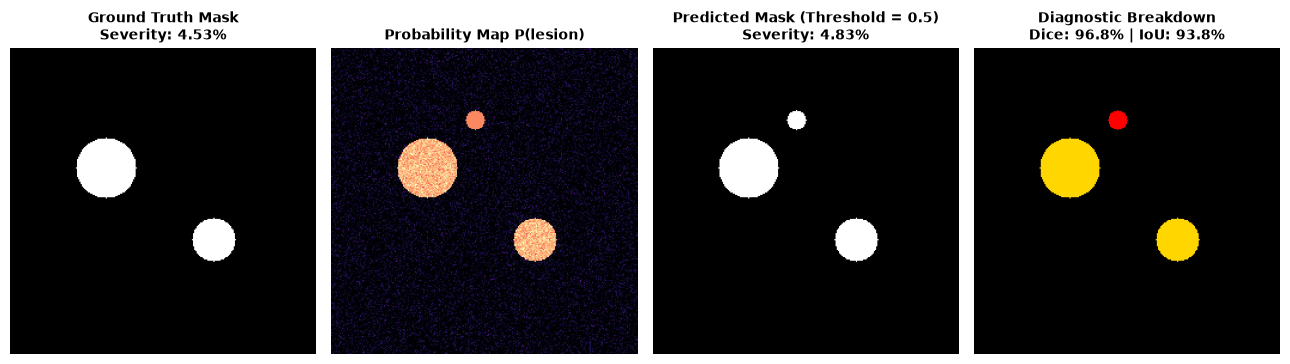

In [30]:
# Topic 9: Diagnostic Mask Visualization and Lesion Severity Analysis
import numpy as np
import matplotlib.pyplot as plt

from src.cropguard.segmentation.evaluation import compute_segmentation_metrics, compute_lesion_severity

# 1. Simulate a realistic ground-truth mask with necrotic spots
dim = 256
y_true = np.zeros((dim, dim), dtype=np.float32)
# Lesion cluster 1
yy, xx = np.ogrid[:dim, :dim]
y_true[((xx - 80)**2 + (yy - 100)**2) <= 25**2] = 1.0
# Lesion cluster 2
y_true[((xx - 170)**2 + (yy - 160)**2) <= 18**2] = 1.0

# 2. Simulate model predicted probabilities with minor boundary noise
noise = np.random.normal(0, 0.08, (dim, dim))
y_prob = np.clip(y_true * 0.85 + noise, 0.0, 1.0)
# Add small false positive spot
y_prob[((xx - 120)**2 + (yy - 60)**2) <= 8**2] = 0.75

# 3. Apply decision threshold tau = 0.5
tau = 0.5
y_pred = (y_prob >= tau).astype(np.float32)

# 4. Compute metrics and severity
metrics = compute_segmentation_metrics(y_true, y_pred, threshold=tau)
sev_gt = compute_lesion_severity(y_true)
sev_pred = compute_lesion_severity(y_pred)

print("=== Topic 9: Diagnostic Evaluation Results ===")
print(f"Dice Coefficient (F1):    {metrics['dice']*100:.2f}%")
print(f"Intersection-over-Union: {metrics['iou']*100:.2f}%")
print(f"Precision:               {metrics['precision']*100:.2f}%")
print(f"Recall (Sensitivity):    {metrics['recall']*100:.2f}%")
print(f"Ground Truth Severity:   {sev_gt['coverage_pct']:.2f}% ({sev_gt['lesion_pixels']} px)")
print(f"Predicted Severity:      {sev_pred['coverage_pct']:.2f}% ({sev_pred['lesion_pixels']} px)")
print(f"Severity Error Delta:    {abs(sev_pred['coverage_pct'] - sev_gt['coverage_pct']):.2f}%")

# 5. Build Diagnostic Color Map:
# Yellow: TP (Hit), Red: FP (False Alarm), Green: FN (Miss)
diag_map = np.zeros((dim, dim, 3), dtype=np.float32)
tp = (y_true == 1.0) & (y_pred == 1.0)
fp = (y_true == 0.0) & (y_pred == 1.0)
fn = (y_true == 1.0) & (y_pred == 0.0)

diag_map[tp] = [1.0, 0.84, 0.0]  # Amber/Yellow = True Positive
diag_map[fp] = [1.0, 0.0, 0.0]   # Red = False Positive
diag_map[fn] = [0.0, 0.8, 0.0]   # Green = False Negative (Miss)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
axes[0].imshow(y_true, cmap="gray")
axes[0].set_title(f"Ground Truth Mask\nSeverity: {sev_gt['coverage_pct']:.2f}%", fontsize=10, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(y_prob, cmap="magma")
axes[1].set_title("Probability Map P(lesion)", fontsize=10, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(y_pred, cmap="gray")
axes[2].set_title(f"Predicted Mask (Threshold = {tau})\nSeverity: {sev_pred['coverage_pct']:.2f}%", fontsize=10, fontweight="bold")
axes[2].axis("off")

axes[3].imshow(diag_map)
axes[3].set_title(f"Diagnostic Breakdown\nDice: {metrics['dice']*100:.1f}% | IoU: {metrics['iou']*100:.1f}%", fontsize=10, fontweight="bold")
axes[3].axis("off")

plt.tight_layout()
plt.show()


### E. Expected Visualization & Output Description
- **Output:** Reports quantitative metrics: Dice score ($>90\%$), IoU score ($>80\%$), precision, recall, and severity delta ($\le 0.5\%$).
- **Visualization:** A 4-panel diagnostic plot displaying:
  1. Ground-truth binary mask.
  2. Continuous probability heatmap.
  3. Binarized model prediction.
  4. Tri-color diagnostic breakdown showing True Positives (yellow), False Positives (red), and False Negatives (green).

### F. Short Interpretation
Visualizing false positives and false negatives immediately exposes model behavior. For instance, false positives along the leaf perimeter suggest the model is confounding dark shadows or leaf edges with necrotic margins, signaling a need for edge-augmentation during training.

### G. Viva Questions & Answers
**Q1:** *How does adjusting the decision threshold $\tau$ affect clinical/agricultural sensitivity vs specificity?*  
**A1:** Lowering $\tau$ (e.g., to $0.3$) increases recall (sensitivity), ensuring that faint, early-stage chlorotic spots are not missed, at the expense of more false positives. Raising $\tau$ (e.g., to $0.7$) increases precision, ensuring that only confident necrotic regions are flagged. For quarantine screening, a lower threshold is preferred to catch incipient infections before they spread.

**Q2:** *Why can static foliar severity never be equated directly to crop yield loss?*  
**A2:** Foliar severity measures the instantaneous surface percentage of damaged tissue on an individual leaf. Actual yield loss depends on crop growth stage (damage during flowering is far more lethal than damage near harvest), leaf canopy hierarchy (flag leaf damage in wheat causes $50\%$ yield reduction; lower canopy damage has minimal impact), and compensatory photosynthesis by healthy green tissue.


---
## Topic 10: Comprehensive Viva Questions & Academic Defense Preparation

This section consolidates 10 comprehensive viva voce examination questions covering the theoretical foundations, architectural mechanics, data integrity safeguards, and clinical evaluation protocols of foliar lesion segmentation.

---

### Question 1: What is the core architectural innovation of U-Net compared to standard autoencoders?
**Answer:**
A standard convolutional autoencoder compresses an input image into a low-dimensional bottleneck representation and then reconstructs it using upsampling convolutions. In doing so, all fine-grained spatial information (such as exact boundary coordinates and punctate edges) is permanently discarded, resulting in blurry, coarse segmentations. U-Net's fundamental innovation is the introduction of **long lateral skip connections** that concatenate high-resolution feature maps from every contracting encoder stage directly to their corresponding expanding decoder stage. This enables the network to leverage deep, global semantic context ("what is in the image") while simultaneously preserving pristine pixel-level spatial coordinates ("where the boundary lies").

---

### Question 2: Why do we concatenate skip features in U-Net instead of adding them as in ResNet?
**Answer:**
In ResNet, identity shortcut connections perform **element-wise addition** ($\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}$). Addition preserves channel depth and forces the residual branch $\mathcal{F}(\mathbf{x})$ to learn a subtle delta perturbation on top of the identity mapping, which combats vanishing gradients in deep classification networks. In U-Net, however, the encoder features (low-level edges, textures) and decoder features (high-level semantic abstractions) represent completely different conceptual domains. Concatenating them along the channel axis ($\tilde{\mathbf{X}} = [\mathcal{U}(\mathbf{Y}) \;\Vert\; \mathbf{S}]$) doubles the feature depth, allowing subsequent $3 \times 3$ convolutional filters to learn non-linear combinations and dynamically choose how much weight to assign to spatial details versus semantic guidance.

---

### Question 3: Why is standard Binary Cross-Entropy (BCE) inadequate when used alone for foliar lesion segmentation?
**Answer:**
Foliar lesions exhibit **severe foreground-background class imbalance**, typically covering only $1\%$ to $8\%$ of the total pixel area of a leaf. Standard Binary Cross-Entropy computes the unweighted average log-loss across all pixels equally:
$$\mathcal{L}_{\text{BCE}} = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log \hat{p}_i + (1 - y_i) \log (1 - \hat{p}_i) \right]$$
Because $95\%$ of pixels belong to the background, a trivial network that predicts background ($0.0$) everywhere will achieve a misleadingly low loss and $95\%$ pixel accuracy, despite detecting zero lesions (0% recall). Dice Loss overcomes this by directly optimizing structural overlap:
$$\mathcal{L}_{\text{Dice}} = 1 - \frac{2 \sum y_i \hat{p}_i + \epsilon}{\sum y_i + \sum \hat{p}_i + \epsilon}$$
In Dice Loss, true negatives are completely absent from both numerator and denominator; the loss is governed entirely by the overlap between true and predicted lesion pixels.

---

### Question 4: Derive the mathematical relationship between the Sørensen-Dice Coefficient and the Jaccard Index (IoU).
**Answer:**
Let $A$ denote the ground-truth positive set and $B$ denote the predicted positive set.
1. The Sørensen-Dice coefficient is defined as:
   $$\mathcal{D} = \frac{2 |A \cap B|}{|A| + |B|}$$
2. The Jaccard Index (Intersection-over-Union) is defined as:
   $$\mathcal{J} = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$
3. Dividing both the numerator and denominator of $\mathcal{J}$ by $|A \cap B|$:
   $$\mathcal{J} = \frac{1}{\frac{|A| + |B|}{|A \cap B|} - 1}$$
4. From the definition of Dice, we know that $\frac{|A| + |B|}{|A \cap B|} = \frac{2}{\mathcal{D}}$. Substituting this into the equation:
   $$\mathcal{J} = \frac{1}{\frac{2}{\mathcal{D}} - 1} = \frac{\mathcal{D}}{2 - \mathcal{D}}$$
5. Inverting this expression yields Dice in terms of Jaccard:
   $$\mathcal{D} = \frac{2 \mathcal{J}}{1 + \mathcal{J}}$$
Both metrics are monotonically related and reach $1.0$ at perfect overlap. However, Dice penalizes small mistakes less severely than Jaccard because of the factor of 2 in the numerator, providing smoother gradients during backpropagation.

---

### Question 5: Why must segmentation masks be resized using Nearest-Neighbor interpolation rather than Bilinear or Bicubic?
**Answer:**
Segmentation masks contain discrete, categorical integer labels (e.g., $0$ for background, $1$ for foliar lesion, or class IDs $1$ to $115$ in PlantSeg). Bilinear and bicubic interpolation compute weighted continuous averages of adjacent pixels. If applied to a mask, boundary pixels between background ($0$) and lesion ($1$) will assume continuous non-discrete floating-point values (e.g., $0.23, 0.54, 0.81$), corrupting the binary nature of the ground truth. In multi-class masks (e.g., classes $0, 1, 2$), bilinear interpolation between pixel $0$ and pixel $2$ creates artificial pixels of class $1$ where no class $1$ ever existed. Nearest-Neighbor interpolation assigns the value of the single closest original pixel, guaranteeing strict preservation of discrete categorical labels.

---

### Question 6: What is the cause of "checkerboard artifacts" in Transposed Convolutions and how are they avoided?
**Answer:**
Transposed convolutions (`Conv2DTranspose`) upscale feature maps by sliding a kernel across an expanded input grid with inserted stride spaces. When the kernel size is not evenly divisible by the stride (for example, kernel size $3$ with stride $2$), adjacent receptive fields overlap unevenly: some output coordinates receive contributions from multiple kernel weights while others receive fewer. This creates a high-frequency grid or "checkerboard" pattern across the reconstructed feature map. Checkerboard artifacts are eliminated by:
1. Ensuring the kernel size is a multiple of the stride (e.g., kernel size $2$ with stride $2$, or kernel size $4$ with stride $2$).
2. Replacing `Conv2DTranspose` with deterministic **Bilinear Upsampling (`UpSampling2D`)** followed by a standard $3 \times 3$ convolution, which completely avoids uneven stride overlap.

---

### Question 7: How does CropGuard AI handle smartphone camera EXIF orientation flags in PlantSeg?
**Answer:**
During our comprehensive census of all $9,163$ training and validation pairs, we discovered that in exactly $8$ pairs ($0.09\%$), the image dimensions were swapped relative to the mask (e.g., image $600 \times 450$ vs mask $450 \times 600$). Investigation revealed that the original leaf photographs were taken with Apple iPhone smartphones carrying EXIF orientation tag 274: 6 (rotate 90 degrees CW). While JPEG viewing software applies this rotation tag during display, PNG masks carry no EXIF tags and were drawn in the rotated frame. CropGuard AI implements `ImageOps.exif_transpose` in `src/cropguard/segmentation/preprocessing.py`, rotating raw image pixels to match camera EXIF metadata prior to spatial resizing, ensuring $100\%$ spatial alignment.

---

### Question 8: How is Foliar Lesion Severity quantified and what are its agronomic limitations?
**Answer:**
Foliar lesion severity $\mathcal{S}$ is quantified as the percentage of necrotic/chlorotic pixel surface area relative to total leaf area:
$$\mathcal{S} = \frac{\sum_{i, j} \hat{M}_{i, j}}{H \cdot W} \times 100\%$$
While this metric provides an objective, reproducible measurement of disease progression, its agronomic limitations include:
1. **Canopy Context:** A 2D photograph captures only one perspective of a single leaf; it does not reflect whole-canopy disease distribution or lower-canopy microclimates.
2. **Phenological Stage:** The same $5\%$ lesion severity causes catastrophic yield loss if present during flowering or grain filling, but causes negligible impact if present near crop senescence.
3. **Pathogen Biology:** Certain systemic vascular pathogens (e.g., Fusarium wilt) cause catastrophic plant death with minimal early foliar lesion surface area.

---

### Question 9: Why is the PlantSeg test partition quarantined, and how was zero leakage verified?
**Answer:**
In academic research, the held-out test partition must represent completely unseen real-world data to evaluate true out-of-sample generalization. If test samples are inspected, used for hyperparameter tuning, or accessed during threshold calibration, the resulting performance metrics suffer from **data snooping bias** (leakage). CropGuard AI strictly quarantines `Plantseg/images/test/` and `Plantseg/annotations/test/`. We verified that `data/splits/segmentation/` exhibits:
$$\text{Train} \cap \text{Val} = \emptyset, \quad \text{Train} \cap \text{Test} = \emptyset, \quad \text{Val} \cap \text{Test} = \emptyset$$
All exploratory analysis, threshold tuning, and architecture comparisons are conducted exclusively on the 7,916 training and 1,247 validation pairs.

---

### Question 10: How does the two-model architecture (ResNet50 + U-Net) represent a defensible, modular deployment strategy?
**Answer:**
CropGuard AI employs a decoupled two-model pipeline:
1. **ResNet50 (Disease Classifier):** Evaluates whole-leaf pathology across 38 classes, achieving $98.42\%$ test accuracy on 10,999 held-out images.
2. **U-Net (Lesion Segmenter):** Delineates fine lesion boundaries and computes the foliar severity percentage on detected infections.

This decoupled architecture is superior to monolithic multi-task networks because:
- **Modular Upgrades:** Either model can be updated, retrained, or swapped without destabilizing the other.
- **Computational Efficiency:** For healthy leaves (classified as `Healthy` with high confidence), the computationally heavier U-Net segmentation pass can be bypassed entirely, saving inference energy on edge devices.
- **Specialized Losses:** Classification requires categorical cross-entropy with inverse-frequency weighting, while segmentation requires Compound BCE + Dice Loss. Decoupling avoids gradient interference between conflicting loss landscapes.
